# Create Underlying Topic Model Using Bertopic

Bertopic Documentation: https://maartengr.github.io/BERTopic/index.html

Citation: 
Grootendorst, M. (2022).
BERTopic: Neural topic modeling with a class-based TF-IDF procedure.
arXiv preprint arXiv:2203.05794.

In [1]:
import pandas as pd
import numpy as np

import re

import nltk
from nltk.tokenize import sent_tokenize

from sentence_transformers import SentenceTransformer

from umap import UMAP

from hdbscan import HDBSCAN

import sklearn
from sklearn.feature_extraction.text import CountVectorizer

import openai

from bertopic.representation import KeyBERTInspired, MaximalMarginalRelevance, OpenAI, PartOfSpeech
from bertopic import BERTopic

import matplotlib.pyplot as plt

from collections import defaultdict

from gensim.corpora import Dictionary
from gensim.models.coherencemodel import CoherenceModel


c:\Users\tegroton\AppData\Local\anaconda3\envs\gensimcapable\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Read In Data

In [2]:
#read in raw review data from grocery store reviews dataset
reviews = pd.read_csv("G:\My Drive\Meeting Reports\Thesis\For_Coding\Final_pipeline\data\grocery_store_reviews_text.csv")

reviews.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32751 entries, 0 to 32750
Data columns (total 43 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   address                  32751 non-null  object 
 1   categoryName             32751 non-null  object 
 2   cid                      32751 non-null  float64
 3   city                     32751 non-null  object 
 4   countryCode              32751 non-null  object 
 5   fid                      32751 non-null  object 
 6   isAdvertisement          32751 non-null  bool   
 7   isLocalGuide             32751 non-null  bool   
 8   language                 32751 non-null  object 
 9   likesCount               32751 non-null  int64  
 10  location/lat             32751 non-null  float64
 11  location/lng             32751 non-null  float64
 12  name                     32751 non-null  object 
 13  originalLanguage         32751 non-null  object 
 14  originalText          

### Preprocess
Basic text cleaning as well as custom stopword removal of all store names and common store name variations. 

In [3]:
custom_stopwords = ['publix', 'harris', 'teeter', 'ht', 'teeters', 'Publix', 'Harris', 'Teeter', 'HT', 'lion', 'Lion','lions', \
                    'aldi', 'Aldi','aldis', 'lidl', 'Lidl', 'Carlie','carlie','wegmans', 'Wegmans', 'sprouts','lowes', 'Lowes', 'trader', 'Trader', \
                        'joes', 'Joes', 'walmart', 'Walmart','kroger', "Kroger", 'Aldis',\
                            'piggly', 'Piggly', 'piggly wiggly', 'Piggly Wiggly', 'pigglywiggly', 'PigglyWiggly', 'wiggly', 'piggy']


def clean_text(text):
    """
    Function to clean text data by removing html tags, punctuation, and lowercasing the text.
    """
    #lowercase text
    text = text.lower()

    #remove html tags
    text = re.sub(r'<.*?>', '', text)

    #remove punctuation
    text = re.sub(r'[^\w\s]', '', text)

    #remove custom stopwords
    text = ' '.join(word for word in text.split() if word not in custom_stopwords)

    return text

In [4]:
#create clean text series
reviews['processed_text'] = reviews['text'].apply(clean_text)

In [5]:
#convert cleaned text into a list for topic model (requires list input)
review_list = reviews['processed_text']

### Embeddings

 `all-miniLM-L12-v2` Model from Sentence Transformers

 **Model Citation**: 
 
 Sentence-Transformers. all-minilm-l12-v2. https://huggingface.co/sentence-transformers/all-MiniLM-L12-v2, 2024. Pretrained embedding model. Accessed November 11, 2025.

 **Model Papers Citations:** 

 
Nils Reimers and Iryna Gurevych. Sentence-BERT: Sentence Embeddings using Siamese BERT-Networks, August 2019. URL http://arxiv.org/abs/1908.10084. arXiv:1908.10084 [cs].

Wenhui Wang, Furu Wei, Li Dong, Hangbo Bao, Nan Yang, and Ming Zhou. MiniLM: Deep Self-Attention Distillation for Task-Agnostic Compression of Pre-Trained Transformers, April 2020. URL http://arxiv.org/abs/2002.10957. arXiv:2002.10957 [cs].

In [6]:
#embed cleaned text using sentence transformer model
embedding_model = SentenceTransformer('all-miniLM-L12-v2')
embeddings = embedding_model.encode(review_list, show_progress_bar=True)

Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Batches: 100%|██████████| 1024/1024 [01:41<00:00, 10.13it/s]


In [7]:
# Pre-reduce embeddings for visualization purposes
reduced_embeddings = UMAP(n_neighbors=15, n_components=2, min_dist=0.05, metric='cosine', random_state=42).fit_transform(embeddings)

### Construct Model Pipeline

Dimensionality Redution with UMAP, tune parameters as needed

In [8]:
umap_model = UMAP(n_neighbors=30, n_components=5, min_dist=0.05, metric='cosine', random_state=42)

Clustering with HDBscan, tune parameters as needed

In [9]:
hdbscan_model = HDBSCAN(min_cluster_size=120, min_samples= 15, metric='euclidean', cluster_selection_method='leaf', prediction_data=True)

This count vectorizer step processes the text after the clustering is complete for readability purposes, it does not affect the clustering. It simply changes the topic representation so it is easier to understand. 

In [10]:
vectorizer_model = CountVectorizer(stop_words='english', min_df=2, ngram_range=(1, 3))

### Additional Representations

In BERTopic, you can model many different topic representations simultanously to test them out and get different perspectives of topic descriptions.

Keybert Representation

In [11]:
keybert_model = KeyBERTInspired()

Maximal Marginal Relevance

In [12]:
mmr_model = MaximalMarginalRelevance(diversity=0.3)

OpenAI topic labels
These labels are really helpful, although you could also manually label. The prompt can be changed based on what you want. It does require an API key, and I removed mine, so it is commented out for now. You could also API to an open source LLM to name them if preferred. 

In [32]:
# GPT-3.5
prompt = """
I have a topic that contains the following documents:
[DOCUMENTS]
The topic is described by the following keywords: [KEYWORDS]

Based on the information above, extract a short topic label for the topic. Make it academic in nature and no more than three words. 
Make sure it is in the following format:
topic: <topic label>
"""
#client = openai.OpenAI(api_key="")
#openai_model = OpenAI(client, model="gpt-3.5-turbo", exponential_backoff=True, chat=True, prompt=prompt)

In [14]:
# All representation models
representation_model = {
    "KeyBERT": keybert_model,
    "MMR": mmr_model,
   #"OpenAI": openai_model
}

## Training

In [15]:
topic_model = BERTopic(

  # Pipeline models
  embedding_model=embedding_model,
  umap_model=umap_model,
  hdbscan_model=hdbscan_model,
  vectorizer_model=vectorizer_model,
  representation_model=representation_model,

  # Hyperparameters
  top_n_words=10,
  verbose=True
)

topics, probs = topic_model.fit_transform(review_list, embeddings)

2026-04-24 10:12:13,417 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-04-24 10:12:45,627 - BERTopic - Dimensionality - Completed ✓
2026-04-24 10:12:45,627 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-04-24 10:12:47,548 - BERTopic - Cluster - Completed ✓
2026-04-24 10:12:47,553 - BERTopic - Representation - Fine-tuning topics using representation models.
100%|██████████| 60/60 [00:36<00:00,  1.65it/s]
2026-04-24 10:13:33,161 - BERTopic - Representation - Completed ✓


## Topics

In [16]:
topic_info = topic_model.get_topic_info()

In [17]:
topic_info

,Topic,Count,Name,Representation,KeyBERT,MMR,OpenAI,Representative_Docs
0,-1,16982,-1_store_good_great_clean,"[store, good, great, clean, food, grocery, ser...","[customer service, customer, customers, cashie...","[store, grocery, friendly, shopping, place, cu...",[Customer Experience in Retail],[two stars cause its not the worse but they co...
1,0,900,0_meat_meats_meat department_butcher,"[meat, meats, meat department, butcher, depart...","[great meat selection, meat dept, best meats, ...","[meats, meat department, butcher, steak, great...",[Meat Department Quality],"[gene in the meat department is fantastic, bes..."
2,1,557,1_groceries_grocery_grocery store_place,"[groceries, grocery, grocery store, place, gro...","[groceries, shop groceries, place groceries, s...","[grocery, grocery store, grocery shopping, gro...",[Grocery Shopping Preferences],"[groceries, they have groceries, groceries]"
3,2,525,2_experience_place_visit_good experience,"[experience, place, visit, good experience, lo...","[good experience, great experience, great expe...","[place, visit, awesome place, love location, l...",[Positive Visit Experiences],"[always a very good experience, i had a good e..."
4,3,514,3_prices_high_quality_low,"[prices, high, quality, low, prices good, chea...","[prices high, prices prices high, high prices,...","[prices good, products, great prices, low pric...",[Price Perception],"[prices too high, prices, prices are betterlower]"
5,4,472,4_store_prices_great store_nice store,"[store, prices, great store, nice store, shop,...","[prices nice store, nice store great, great st...","[great store, nice store, store good, love sto...",[Consumer behavior in retail],"[nice store great prices, great store with gre..."
6,5,456,5_clean store_clean_store clean_store,"[clean store, clean, store clean, store, nice ...","[nice clean store, good store clean, great sto...","[clean store, nice clean store, clean store gr...",[Clean Retail Environment],"[very clean store, its a very clean store, ver..."
7,6,441,6_sausage_country_smiths_best,"[sausage, country, smiths, best, christmas, ca...","[sausage, sausage best, sausage good, make sau...","[sausage, country, smiths, christmas, candy, l...",[Sausage Analysis],"[sausage, sausage, sausage is greatget some]"
8,7,433,7_food_staff_friendly_service,"[food, staff, friendly, service, great, helpfu...","[food great service, service great food, great...","[love food, food staff, good food, customer se...",[Food Service Quality],"[great food great service, always the best cus..."
9,8,405,8_needed_need_looking_need need,"[needed, need, looking, need need, needed need...","[got needed, just needed, got needed got, need...","[need, looking needed, wanted, needed quickly,...",[Consumer Needs Analysis],"[i found what i needed, they had what i needed..."


### Full Model Visualizations

In [18]:
topic_model.visualize_barchart(top_n_topics=300, n_words=10)

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'marker': {'color': '#D55E00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.01346550691026479, 0.015708786112376603,
                    0.01650094110702556, 0.01689400705623634, 0.018760155977851474,
                    0.019266152305964714, 0.019456036933112576,
                    0.023101678647851426, 0.05725051742639391, 0.06667889497828561],
              'xaxis': 'x',
              'y': [prices  , great  , great meat  , steaks  , beef  , department
                    , butcher  , meat department  , meats  , meat  ],
              'yaxis': 'y'},
             {'marker': {'color': '#0072B2'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.011945799105184032, 0.012473015977093261,
                    0.012548646204363707, 0.013695367142443474,
                    0.01537615352981386, 0.015494175566915167,
                    0.016058435952273964, 0.025012534655266917,
                    0.03775174620186994, 0.04463237888067529],
              'xaxis': 'x2',
              'y': [grocery stores  , prices  , stores  , shopping  , store  ,
                    grocery shopping  , place  , grocery store  , grocery  ,
                    groceries  ],
              'yaxis': 'y2'},
             {'marker': {'color': '#CC79A7'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.02220423635606915, 0.022840714813037098,
                    0.026989829168392744, 0.02932518967824036,
                    0.030102635947772155, 0.046448783590643604,
                    0.047119842841151394, 0.05094885307222713, 0.05268344020563675,
                    0.06971979008549713],
              'xaxis': 'x3',
              'y': [close  , home  , love  , time  , great experience  , location
                    , good experience  , visit  , place  , experience  ],
              'yaxis': 'y3'},
             {'marker': {'color': '#E69F00'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.031538806272940284, 0.03159966393130679,
                    0.032328775593409666, 0.034735425051394035,
                    0.035487252803546775, 0.03574475614899301,
                    0.037102354816860666, 0.0432272643371419, 0.05271719968324799,
                    0.0901449623855164],
              'xaxis': 'x4',
              'y': [price  , prices high  , good  , pricey  , cheap  , prices good
                    , low  , quality  , high  , prices  ],
              'yaxis': 'y4'},
             {'marker': {'color': '#56B4E9'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.015640380061983403, 0.016065960655144092,
                    0.01691169087449222, 0.01838358031328162, 0.020529133754473492,
                    0.021833338038091434, 0.024278753157505325,
                    0.030657860930437725, 0.03085708562066712, 0.03762932914600323],
              'xaxis': 'x5',
              'y': [good  , new store  , stores  , store great  , great  , shop  ,
                    nice store  , great store  , prices  , store  ],
              'yaxis': 'y5'},
             {'marker': {'color': '#009E73'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.019807326098270794, 0.020157598817751424,
                    0.023101645062888646, 0.026758735602843153,
                    0.030045855280975677, 0.03193497775897226, 0.04122173056580273,
                    0.04961496387432863, 0.07251968486563316, 0.07933828275142978],
              'xaxis': 'x6',
              'y': [store clean store  , clean store clean  , nice  , clean store
                    great  , nice clean store  , nice clean  , store  , store clean
                    , clean  , clean store  ],
              'yaxis': 'y6'},
             {'marker': {'color': '#F0E442'},
              'orientation': 'h',
              'type': 'bar',
              'x': [0.023000034270

In [19]:
topic_model.visualize_hierarchy()

ValueError: Mime type rendering requires nbformat>=4.2.0 but it is not installed

Figure({
    'data': [{'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAADG+9oLg3HjP8b72guDceM/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAAFMAAAAAAAAAUwAAAAAAAAC7AAAAAAAAALsA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAACUhDGZyNvaP5SEMZnI29o/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAAOcAAAAAAAAA5wAAAAAAAgEHAAAAAAACAQcA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(61,153,112)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'xvvaC4Nx4z8T3QYPRQnpPxPdBg9FCek/lIQxmcjb2j8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAAJMAAAAAAAAAkwAAAAAAAAD7AAAAAAAAAPsA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(255,65,54)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAADgUezncrXgP+BR7OdyteA/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAACAS8AAAAAAAIBLwAAAAAAAQFDAAAAAAABAUMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(255,65,54)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAADuv+6brd/iP+6/7put3+I/4FHs53K14D8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAACARsAAAAAAAIBGwAAAAAAAAE7AAAAAAAAATsA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(255,65,54)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAABZU4Shd/HlP1lThKF38eU/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAADAUsAAAAAAAMBSwAAAAAAAQFXAAAAAAABAVcA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(255,65,54)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': '7r/um63f4j/WjEE5J6zsP9aMQTknrOw/WVOEoXfx5T8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAABASsAAAAAAAEBKwAAAAAAAAFTAAAAAAAAAVMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(0,116,217)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'E90GD0UJ6T8a/oZY1AjzPxr+hljUCPM/1oxBOSes7D8=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAAAANMAAAAAAAAA0wAAAAAAAkFDAAAAAAACQUMA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(35,205,205)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAAB0qP+6o+7mP3So/7qj7uY/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAADAV8AAAAAAAMBXwAAAAAAAQFrAAAAAAABAWsA=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
              'marker': {'color': 'rgb(133,20,75)'},
              'mode': 'lines',
              'type': 'scatter',
              'x': {'bdata': 'AAAAAAAAAACoyl7UF47vP6jKXtQXju8/AAAAAAAAAAA=', 'dtype': 'f8'},
              'xaxis': 'x',
              'y': {'bdata': 'AAAAAADAXMAAAAAAAMBcwAAAAAAAQF/AAAAAAABAX8A=', 'dtype': 'f8'},
              'yaxis': 'y'},
             {'hoverinfo': 'text',
  

Calculating medoids:   0%|          | 0/55 [00:00<?, ?it/s]

Calculating medoids: 100%|██████████| 55/55 [00:04<00:00, 13.22it/s]


(<Figure size 1000x1000 with 1 Axes>,
 <Axes: title={'left': 'Topics labeled with `GPT 3.5`'}>)

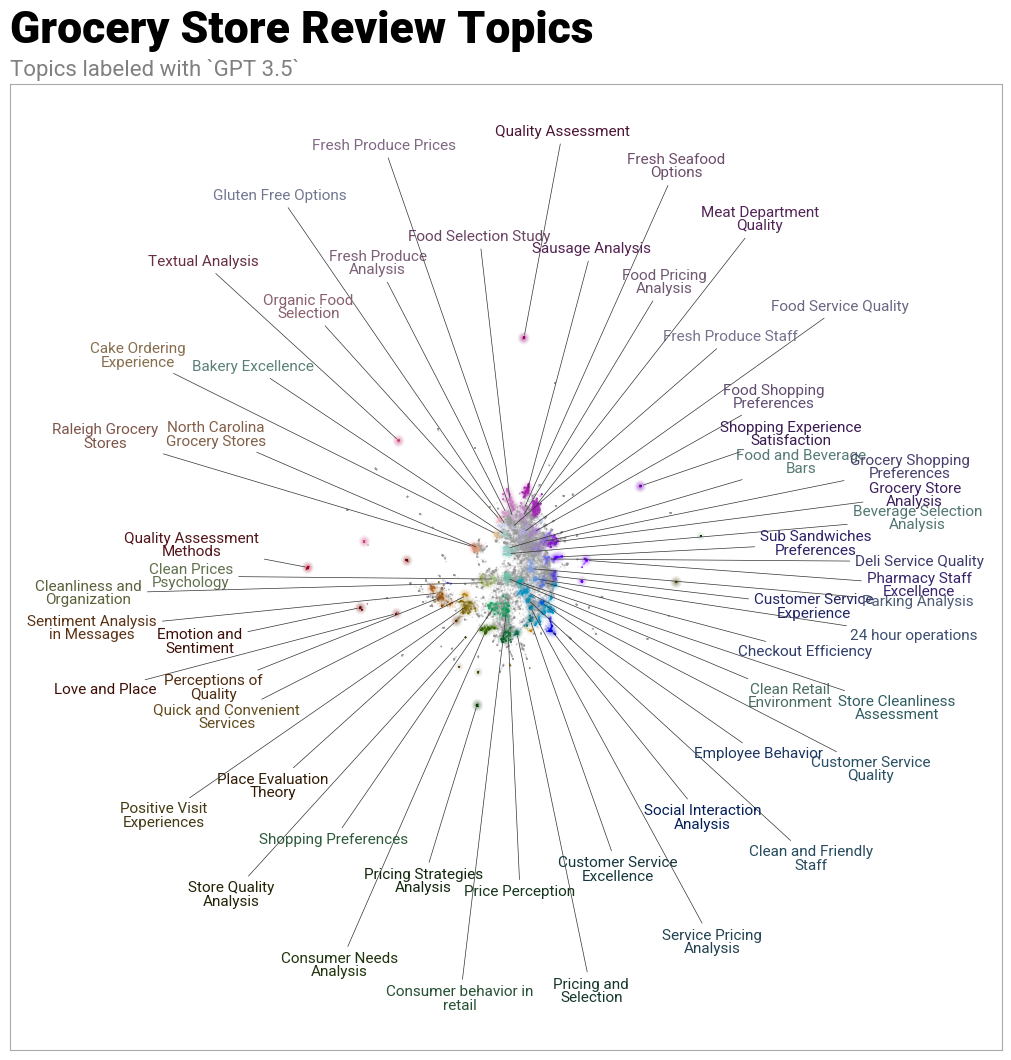

In [20]:
import datamapplot

# Create a label for each document
llm_labels = [re.sub(r'\W+', ' ', label[0][0].split("\n")[0].replace('"', '')) for label in topic_model.get_topics(full=True)["OpenAI"].values()]
llm_labels = [label if label else "Unlabelled" for label in llm_labels]
all_labels = [llm_labels[topic+topic_model._outliers] if topic != -1 else "Unlabelled" for topic in topics]

# Run the visualization
datamapplot.create_plot(
    reduced_embeddings,
    all_labels,
    label_font_size=11,
    title="Grocery Store Review Topics",
    sub_title="Topics labeled with `GPT 3.5`",
    label_wrap_width=20,
    use_medoids=True
)

## Evaluating Model

### Gensim Coherence
Using Gensim Coherence model for scoring as that is standard in the literature. Using this model requires some manipulation of our Bertopic results in order to get the coherence score, because Gensim expects some different outputs. Additionally Gensim tends to cause package version issues, so if you are having issues, its probably an environment problem.

Gensim Coherence Citation: 
Michael Röder, Andreas Both, and Alexander Hinneburg. Exploring the Space of Topic Coher-
ence Measures. In Proceedings of the Eighth ACM International Conference on Web Search and
Data Mining, pages 399–408, Shanghai China, February 2015. ACM. ISBN 978-1-4503-3317-7.
doi: 10.1145/2684822.2685324. URL https://dl.acm.org/doi/10.1145/2684822.2
685324.

In [21]:
#coherence requires a list of tokenized documents and a dictionary mapping of word ids to words

def extract_top_words_from_bertopic(model, topn=10, drop_outlier=True):
    """
    Pulls the top-N c-TF-IDF words per topic from a BERTopic model.
    Returns:
        topic_words:  {topic_id: [w1,...,wN]}
    """
    topics = model.get_topics()  # {topic_id: [(word, score), ...]}
    topic_words = {}
    for k, ws in topics.items():
        if drop_outlier and k == -1:
            continue
        if not ws:
            continue
        topic_words[k] = [w for w, _ in ws[:topn]]
    return topic_words

In [22]:
# Compute C_v coherence for BERTopic topics
def compute_cv_coherence(topic_words_dict, texts_tokenized, *, window_size=110):
    """
    Compute C_v coherence for each topic and an overall mean.

    Args
    ----
    topic_words_dict : dict[int, list[str]]
        From extract_top_words_from_bertopic (top words per topic).
    texts_tokenized  : list[list[str]]
        Your corpus as token lists (use the same preprocessing you used for the model).
    window_size      : int
        Sliding-window size for co-occurrence (110 is the Röder et al. default used by gensim).
    processes        : int or None
        Parallel workers for gensim's CoherenceModel (None lets gensim decide).

    Returns
    -------
    {
      "per_topic": {topic_id: cv_score, ...},
      "overall": float
    }
    """
    # Stable order for mapping scores back to topic ids
    topic_ids = sorted(topic_words_dict.keys())
    topics_list = [topic_words_dict[k] for k in topic_ids]

    # Dictionary is only used to build the internal vocab for C_v
    dictionary = Dictionary(texts_tokenized)

    cm = CoherenceModel(
        topics=topics_list,
        texts=texts_tokenized,
        dictionary=dictionary,
        coherence="c_v",
        window_size=window_size
    )
    per_topic = cm.get_coherence_per_topic()
    overall = float(np.mean(per_topic)) if per_topic else float("nan")
    return {"per_topic": dict(zip(topic_ids, per_topic)), "overall": overall}

In [23]:
from sklearn.feature_extraction.text import CountVectorizer

# To compute coherence, you need to re-tokenize your texts with the same analyzer that BERTopic used during training. 
# This ensures that the tokenization and preprocessing steps are consistent when computing coherence scores.

# 1) Get the exact analyzer BERTopic used (includes n-gram range, stopwords, etc.)
vec = getattr(topic_model, "vectorizer_model", None)
analyzer = vec.build_analyzer()

# 2) Re-tokenize your texts with that analyzer (IMPORTANT: pass raw strings)
texts_tokenized = [analyzer(t) for t in review_list]

In [24]:
#extract top words, compute coherence, and print overall score
topic_words = extract_top_words_from_bertopic(topic_model, topn=10, drop_outlier=True)
coherence = compute_cv_coherence(topic_words, texts_tokenized, window_size=110)
coherence['overall']

0.5275345734138441

### Topic Diversity and Uniqueness

In addition to coherence, we want to evaluate how distinct our topics are. Topic Diversity is a basic way to evaluate the keywords of a topic against all keywords to see how diverse the topics are, it yields a score between 0 and 1. Topic uniqueness is a within topic score of each keyword. 



In [25]:
# different version of extract_top_words that also returns the c-TF-IDF scores for each word

def extract_top_words_scores_from_bertopic(model, topn=10, drop_outlier=True):
    """
    Returns:
        topic_words: dict[int, list[str]]       # topic_id -> list of topn words
        topic_scores: dict[int, list[float]]    # topic_id -> c-TF-IDF scores (aligned with words)
    """
    topics = model.get_topics()  # {topic_id: [(word, score), ...]}
    topic_words, topic_scores = {}, {}

    for k, ws in topics.items():
        if k == -1 and drop_outlier:
            continue
        if not ws:
            continue
        words = [w for w, s in ws[:topn]]
        scores = [s for w, s in ws[:topn]]
        topic_words[k] = words
        topic_scores[k] = scores

    return topic_words, topic_scores

In [26]:
def topic_uniqueness_and_diversity(topic_words_dict, topn=None):
    """
    Returns:
        per_topic_uniqueness: {topic_id: TU_k}
        model_topic_diversity: float in [0,1]
    """
    # normalize to topn if requested
    if topn is not None:
        tw = {k: v[:topn] for k, v in topic_words_dict.items()}
        N = topn
    else:
        # assume all same length; fall back to min length
        minN = min(len(v) for v in topic_words_dict.values())
        tw = {k: v[:minN] for k, v in topic_words_dict.items()}
        N = minN

    # word -> set of topics it appears in
    word_topics = defaultdict(set)
    for k, words in tw.items():
        for w in set(words):
            word_topics[w].add(k)

    per_topic_uniqueness = {}
    for k, words in tw.items():
        uniq = sum(1 for w in words if len(word_topics[w]) == 1)
        per_topic_uniqueness[k] = uniq / float(N)

    # Topic Diversity (TD)
    total = len(tw) * N
    unique_word_count = sum(1 for w, ts in word_topics.items() if len(ts) >= 1)  # union size
    model_topic_diversity = unique_word_count / float(total)

    return per_topic_uniqueness, model_topic_diversity

In [30]:
#find uniqueness and diversity of topics
#TD is the proportion of unique words across all topics (union) relative to the total number of words (number of topics * topn).
# A higher TD indicates more distinct topics with less overlap in their top words. 
# TU is the proportion of unique words within a topic relative to the number of top words. 
# A higher TU indicates that a topic has more unique words that do not appear in other topics, suggesting it is more distinct.
topic_words, topic_scores = extract_top_words_scores_from_bertopic(topic_model, topn=10, drop_outlier=True)

# Uniqueness + Diversity
per_topic_TU, TD = topic_uniqueness_and_diversity(topic_words, topn=10)
print("Topic Diversity (TD):", TD)  # model-level
print(sorted(per_topic_TU.items())[:10])


Topic Diversity (TD): 0.7084745762711865
[(0, 0.7), (1, 0.3), (2, 0.7), (3, 0.7), (4, 0.1), (5, 0.4), (6, 0.9), (7, 0.1), (8, 1.0), (9, 0.2)]


### Saving Model
Model must be saved for future use to continue this method. This was the final model saved after many rounds of hyperparameter tuning. The final model was chosen based on coherence score, topic diversity score, and manual evaluation of topics.

In [31]:
#embedding_model = "sentence-transformers/all-MiniLM-L12-v2"
#topic_model.save("bertopic_model", serialization="safetensors", save_ctfidf=True, save_embedding_model=embedding_model)